# E-Commerce Sales Data Analysis & Insights
## End-to-End Exploratory Data Analysis & Data Engineering Pipeline
**Author:** AI / Data Engineering Portfolio Project  
**Tech Stack:** Python 3.11, Pandas, NumPy, Matplotlib, Seaborn  
**Environment:** Apple Silicon (macOS ARM64, M2, 16 GB RAM)

---

### 1. Project Introduction
Exploratory Data Analysis (EDA) is the essential foundation of AI and Machine Learning engineering. Before building predictive models (regression, classification, clustering, or forecasting), an AI Engineer must rigorously investigate raw data distributions, audit data quality, validate schema integrity, and extract domain-relevant features without introducing target leakage or destructive data loss.

```text
Raw Tabular Data ──> Quality Audit & Cleaning ──> Feature Engineering ──> Statistical Profiling ──> Multi-Dimensional GroupBy ──> Visualizations ──> Evidence-Based Insights ──> ML Readiness
```


## 2. Business Questions
This project investigates 10 targeted commercial questions:
1. **Category Revenue:** Which product category generates the highest total sales volume?
2. **Category Profitability:** How does net profitability and profit margin vary across categories?
3. **Geographic Distribution:** What are the key regional revenue drivers across the United States?
4. **Time-Series Trajectory:** How do sales evolve chronologically across 2014–2017, and what seasonal patterns exist?
5. **Distribution Skewness:** How are line-item sales distributed, and how does a log transformation impact skewness?
6. **Top Products:** Which products drive top-line revenue vs. bottom-line profitability?
7. **Volume vs. Sales:** What is the empirical relationship between units ordered and gross revenue?
8. **Feature Associations:** What linear relationships exist across numerical transaction variables?
9. **Discount Impact:** How does applied promotional discounting associate with aggregate profitability?
10. **Margin Efficiency:** How do category profit margins compare with total gross sales rankings?


## 3. Environment Setup & Library Imports
We configure lightweight, high-performance scientific computing libraries with modular architecture imports from `src/`.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to sys.path
project_root = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_cleaning import (
    load_raw_data,
    standardize_column_names,
    convert_datetime_columns,
    add_date_features,
    calculate_unit_price,
    validate_data_integrity,
    detect_outliers_iqr,
    clean_dataset
)

from src.analysis import (
    calculate_core_kpis,
    calculate_distribution_statistics,
    calculate_category_metrics,
    calculate_regional_metrics,
    calculate_segment_metrics,
    calculate_customer_metrics,
    calculate_product_metrics,
    calculate_discount_impact_metrics,
    calculate_correlations
)

from src.visualization import (
    plot_sales_by_category,
    plot_profit_by_category,
    plot_sales_by_region,
    plot_monthly_sales_trend,
    plot_sales_distribution,
    plot_top_products_by_revenue,
    plot_quantity_vs_sales,
    plot_correlation_heatmap,
    plot_discount_profitability,
    plot_category_profit_margin,
    generate_all_visualizations
)

# Visualization styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['axes.edgecolor'] = '#d0d5dd'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

print(f"Pandas version: {pd.__version__}")
print(f"NumPy version:  {np.__version__}")


Pandas version: 3.0.6
NumPy version:  2.4.6


## 4. Load Dataset
We load `data/raw/sales.csv` with standard character encoding while maintaining the raw file untouched.


In [2]:
raw_data_path = project_root / 'data' / 'raw' / 'sales.csv'
df_raw = load_raw_data(raw_data_path, encoding='windows-1252')

print(f"Raw Dataset Loaded: {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
display(df_raw.head(3))


Raw Dataset Loaded: 9,994 rows, 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714


## 5. Dataset Overview & Schema Inspection
Inspecting schema data types and column structures:


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

## 6. Data Quality Assessment

### Core Engineering Principle: Data Cleaning $\neq$ Deleting Unusual Data
In AI/ML engineering, indiscriminately dropping unusual records introduces severe **selection bias**.
- **Valid modifications:** Standardizing column headers to `snake_case`, parsing date strings to `datetime64[ns]`, and verifying boundary constraints ($Q > 0, \text{Sales} \ge 0$).
- **Valid retentions:** Retaining negative profit records (legitimate commercial loss from promotional discounting) and high-value orders (genuine enterprise transactions).


In [4]:
# Missing values audit
missing_counts = df_raw.isnull().sum()
missing_df = pd.DataFrame({'Missing Count': missing_counts, 'Missing %': (missing_counts / len(df_raw)) * 100})
print("=== MISSING VALUES AUDIT ===")
display(missing_df[missing_df['Missing Count'] > 0] if (missing_counts > 0).any() else "Zero missing values detected across all raw columns.")

# Duplicate records audit
duplicate_count = df_raw.duplicated().sum()
print(f"\nExact Duplicate Rows: {duplicate_count}")


=== MISSING VALUES AUDIT ===


'Zero missing values detected across all raw columns.'


Exact Duplicate Rows: 0


### Statistical Outlier Identification (IQR Method)
$$\text{IQR} = Q_3 - Q_1,\quad \text{Lower Bound} = Q_1 - 1.5\times\text{IQR},\quad \text{Upper Bound} = Q_3 + 1.5\times\text{IQR}$$
Outliers are detected and documented for analytical transparency, NOT deleted.


In [5]:
cleaned_sample = standardize_column_names(df_raw)
outlier_report = detect_outliers_iqr(cleaned_sample)

outlier_summary = []
for col, metrics in outlier_report.items():
    outlier_summary.append({
        'Feature': col,
        'Q1 (25%)': f"{metrics['q1']:.2f}",
        'Median': f"{metrics['median']:.2f}",
        'Q3 (75%)': f"{metrics['q3']:.2f}",
        'IQR': f"{metrics['iqr']:.2f}",
        'Lower Bound': f"{metrics['lower_bound']:.2f}",
        'Upper Bound': f"{metrics['upper_bound']:.2f}",
        'Outlier Count': metrics['outlier_count'],
        'Outlier %': f"{metrics['outlier_percentage']}%"
    })

pd.DataFrame(outlier_summary)


,Feature,Q1 (25%),Median,Q3 (75%),IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
0,sales,17.28,54.49,209.94,192.66,-271.71,498.93,1167,11.68%
1,profit,1.73,8.67,29.36,27.64,-39.72,70.82,1881,18.82%
2,quantity,2.00,3.00,5.00,3.00,-2.50,9.50,170,1.7%
3,discount,0.00,0.20,0.20,0.20,-0.30,0.50,856,8.57%


## 7. Data Cleaning Pipeline
We execute the standardized data cleaning pipeline:
1. Standardize column names (`snake_case`).
2. Convert date strings to `datetime64[ns]`.
3. Validate data integrity without deleting records.


In [6]:
processed_data_path = project_root / 'data' / 'processed' / 'cleaned_sales.csv'

df_cleaned, val_report, outlier_report = clean_dataset(
    raw_path=raw_data_path,
    output_path=processed_data_path,
    raise_on_error=True
)

print("=== DATA INTEGRITY VALIDATION ===")
print(f"Raw Dimensions:        {val_report['raw_rows']:,} rows x {val_report['raw_columns']} columns")
print(f"Cleaned Dimensions:    {val_report['cleaned_rows']:,} rows x {val_report['cleaned_columns']} columns")
print(f"Total Null Values:     {val_report['total_missing_values']}")
print(f"Unique Orders:         {val_report['unique_orders']:,}")
print(f"Unique Customers:      {val_report['unique_customers']:,}")
print(f"Invalid Quantities:    {val_report['invalid_quantities_count']}")
print(f"Negative Sales:        {val_report['negative_sales_count']}")
print(f"Invalid Shipping Date: {val_report['invalid_shipping_dates_count']}")
print(f"Preserved Rows:        100.0% (Zero record deletion)")


=== DATA INTEGRITY VALIDATION ===
Raw Dimensions:        9,994 rows x 21 columns
Cleaned Dimensions:    9,994 rows x 28 columns
Total Null Values:     0
Unique Orders:         5,009
Unique Customers:      793
Invalid Quantities:    0
Negative Sales:        0
Invalid Shipping Date: 0
Preserved Rows:        100.0% (Zero record deletion)


## 8. Feature Engineering
We derive temporal, fulfillment, and pricing features:
- `order_year`: Calendar year ($2014 - 2017$)
- `order_month`: Integer month ($1 - 12$)
- `order_month_name`: Short month name (`Jan` - `Dec`)
- `order_quarter`: Fiscal / calendar quarter ($1 - 4$)
- `order_year_month`: Chronological period string (`YYYY-MM`)
- `shipping_days`: Fulfillment duration ($(\text{ship\_date} - \text{order\_date}).\text{days}$)
- `unit_price`: Derived baseline price $(\text{sales} / \text{quantity})$


In [7]:
display(df_cleaned[['order_id', 'order_date', 'ship_date', 'shipping_days', 'category', 'sales', 'quantity', 'unit_price', 'profit']].head())


,order_id,order_date,ship_date,shipping_days,category,sales,quantity,unit_price,profit
0,CA-2016-152156,2016-11-08,2016-11-11,3,Furniture,261.9600,2,130.98,41.9136
1,CA-2016-152156,2016-11-08,2016-11-11,3,Furniture,731.9400,3,243.98,219.5820
2,CA-2016-138688,2016-06-12,2016-06-16,4,Office Supplies,14.6200,2,7.31,6.8714
3,US-2015-108966,2015-10-11,2015-10-18,7,Furniture,957.5775,5,191.52,-383.0310
4,US-2015-108966,2015-10-11,2015-10-18,7,Office Supplies,22.3680,2,11.18,2.5164


## 9. Business KPI Analysis

### Educational Concept: Line-Item Metrics vs. Order-Level Metrics
- **Mean Sales per Line Item:** `df['sales'].mean()` = **$229.86**
- **Average Order Value (AOV):** `df.groupby('order_id')['sales'].sum().mean()` = **$458.61**

Because customer orders contain an average of 2.0 items, evaluating at the basket level is required for commercial validity.


In [8]:
kpis = calculate_core_kpis(df_cleaned)

kpi_table = pd.DataFrame([
    {"Business Metric": "Total Gross Revenue", "Value": f"${kpis['total_revenue']:,.2f}"},
    {"Business Metric": "Total Net Profit", "Value": f"${kpis['total_profit']:,.2f}"},
    {"Business Metric": "Overall Profit Margin", "Value": f"{kpis['overall_profit_margin_pct']}%"},
    {"Business Metric": "Total Units Sold", "Value": f"{kpis['total_quantity_sold']:,}"},
    {"Business Metric": "Total Unique Orders", "Value": f"{kpis['total_orders']:,}"},
    {"Business Metric": "Total Unique Customers", "Value": f"{kpis['total_customers']:,}"},
    {"Business Metric": "Average Order Value (AOV)", "Value": f"${kpis['avg_order_value']:,.2f}"},
    {"Business Metric": "Median Order Value", "Value": f"${kpis['median_order_value']:,.2f}"},
    {"Business Metric": "Average Profit per Order", "Value": f"${kpis['avg_profit_per_order']:,.2f}"},
    {"Business Metric": "Median Profit per Order", "Value": f"${kpis['median_profit_per_order']:,.2f}"},
    {"Business Metric": "Mean Sales per Line Item", "Value": f"${kpis['avg_sales_per_line_item']:,.2f}"},
    {"Business Metric": "Median Sales per Line Item", "Value": f"${kpis['median_sales_per_line_item']:,.2f}"},
    {"Business Metric": "Profitable Orders", "Value": f"{kpis['profitable_orders_count']:,} ({kpis['profitable_orders_pct']}%)"},
    {"Business Metric": "Loss-Making Orders", "Value": f"{kpis['loss_making_orders_count']:,} ({kpis['loss_making_orders_pct']}%)"},
    {"Business Metric": "Break-Even Orders", "Value": f"{kpis['breakeven_orders_count']:,} ({kpis['breakeven_orders_pct']}%)"}
])

display(kpi_table)


,Business Metric,Value
0,Total Gross Revenue,"$2,297,200.86"
1,Total Net Profit,"$286,397.02"
2,Overall Profit Margin,12.47%
3,Total Units Sold,"37,873"
4,Total Unique Orders,"5,009"
5,Total Unique Customers,793
6,Average Order Value (AOV),$458.61
7,Median Order Value,$151.96
8,Average Profit per Order,$57.18
9,Median Profit per Order,$16.28


## 10. Descriptive Statistics & Distribution Profiling
Comparing parametric (mean, std) and non-parametric (median, IQR) measures reveals right-skewness in financial variables ($S = +12.97$ for sales).

> **Statistical Note:** The raw sales distribution is strongly right-skewed, and a logarithmic transformation produces a more symmetric representation.


In [9]:
dist_stats = calculate_distribution_statistics(df_cleaned)
display(dist_stats)


,Feature,Count,Mean,Median,Std Dev,Variance,Min,Q1 (25%),Q3 (75%),IQR,Max,Skewness,Distribution Shape
0,sales,9994,229.86,54.49,623.25,388434.46,0.44,17.28,209.94,192.66,22638.48,12.97,Strongly Right-Skewed (log transformation prod...
1,profit,9994,28.66,8.67,234.26,54877.80,-6599.98,1.73,29.36,27.64,8399.98,7.56,Strongly Right-Skewed (log transformation prod...
2,quantity,9994,3.79,3.00,2.23,4.95,1.00,2.00,5.00,3.00,14.00,1.28,Moderately Right-Skewed
3,unit_price,9994,60.92,16.27,142.93,20428.26,0.34,5.47,63.94,58.47,3773.08,10.78,Strongly Right-Skewed (log transformation prod...
4,discount,9994,0.16,0.20,0.21,0.04,0.00,0.00,0.20,0.20,0.80,1.68,Moderately Right-Skewed
5,shipping_days,9994,3.96,4.00,1.75,3.05,0.00,3.00,5.00,2.00,7.00,-0.42,Fairly Symmetric


## 11. Category & Sub-Category Analysis
Evaluating sales, profit, quantity, and margins across product hierarchies:


In [10]:
cat_summary = calculate_category_metrics(df_cleaned, group_col='category')
display(cat_summary)

subcat_summary = calculate_category_metrics(df_cleaned, group_col='sub_category')
display(subcat_summary.head(10))


,category,total_sales,total_profit,total_quantity,order_line_count,unique_orders,avg_unit_price,profit_margin_pct,sales_share_pct,profit_share_pct
0,Technology,836154.03,145454.95,6939,1847,1544,120.39,17.40,36.4,50.79
1,Furniture,741999.80,18451.27,8028,2121,1764,90.85,2.49,32.3,6.44
2,Office Supplies,719047.03,122490.80,22906,6026,3742,32.15,17.04,31.3,42.77


,sub_category,total_sales,total_profit,total_quantity,order_line_count,unique_orders,avg_unit_price,profit_margin_pct,sales_share_pct,profit_share_pct
0,Phones,330007.05,44515.73,3289,889,814,101.13,13.49,14.37,15.54
1,Chairs,328449.10,26590.17,2356,617,576,138.80,8.10,14.30,9.28
2,Storage,223843.61,21278.83,3158,846,777,70.45,9.51,9.74,7.43
3,Tables,206965.53,-17725.48,1241,319,307,165.09,-8.56,9.01,-6.19
4,Binders,203412.73,30221.76,5974,1523,1316,36.67,14.86,8.85,10.55
5,Machines,189238.63,3384.76,440,115,112,423.35,1.79,8.24,1.18
6,Accessories,167380.32,41936.64,2976,775,718,55.36,25.05,7.29,14.64
7,Copiers,149528.03,55617.82,234,68,68,601.02,37.20,6.51,19.42
8,Bookcases,114880.00,-3472.56,868,228,224,131.10,-3.02,5.00,-1.21
9,Appliances,107532.16,18138.01,1729,466,451,60.62,16.87,4.68,6.33


## 12. Regional & Segment Analysis
Evaluating geographic performance and customer segment contributions:


In [11]:
reg_summary = calculate_regional_metrics(df_cleaned)
display(reg_summary)

seg_summary = calculate_segment_metrics(df_cleaned)
display(seg_summary)


,region,total_sales,total_profit,total_quantity,unique_orders,unique_customers,profit_margin_pct,sales_share_pct,profit_share_pct
0,West,725457.82,108418.45,12266,1611,686,14.94,31.58,37.86
1,East,678781.24,91522.78,10618,1401,674,13.48,29.55,31.96
2,Central,501239.89,39706.36,8780,1175,629,7.92,21.82,13.86
3,South,391721.90,46749.43,6209,822,512,11.93,17.05,16.32


,segment,total_sales,total_profit,total_quantity,unique_orders,unique_customers,profit_margin_pct,avg_revenue_per_order,avg_revenue_per_customer,sales_share_pct
0,Consumer,1161401.34,134119.21,19521,2586,409,11.55,449.11,2839.61,50.56
1,Corporate,706146.37,91979.13,11608,1514,236,13.03,466.41,2992.15,30.74
2,Home Office,429653.15,60298.68,6744,909,148,14.03,472.67,2903.06,18.70


## 13. Customer Analysis
Investigating customer revenue distributions and top accounts:


In [12]:
cust_dist, top_customers = calculate_customer_metrics(df_cleaned, top_n=5)
display(cust_dist)
print("\n=== TOP 5 CUSTOMERS BY REVENUE ===")
display(top_customers[['customer_id', 'customer_name', 'segment', 'total_sales', 'total_profit', 'order_count', 'avg_order_value']])


,Metric,Value
0,Total Unique Customers,793
1,Mean Revenue per Customer,"$2,896.85"
2,Median Revenue per Customer,"$2,256.39"
3,Mean Profit per Customer,$361.16
4,Mean Orders per Customer,6.32
5,Max Orders by a Single Customer,17



=== TOP 5 CUSTOMERS BY REVENUE ===


,customer_id,customer_name,segment,total_sales,total_profit,order_count,avg_order_value
0,SM-20320,Sean Miller,Home Office,25043.05,-1980.74,5,5008.61
1,TC-20980,Tamara Chand,Corporate,19052.22,8981.32,5,3810.44
2,RB-19360,Raymond Buch,Consumer,15117.34,6976.10,6,2519.56
3,TA-21385,Tom Ashbrook,Home Office,14595.62,4703.79,4,3648.90
4,AB-10105,Adrian Barton,Consumer,14473.57,5444.81,10,1447.36


## 14. Product Analysis
Examining revenue leaders, profit leaders, and loss-leader products:


In [13]:
prod_insights = calculate_product_metrics(df_cleaned, top_n=5)

print("=== TOP 5 PRODUCTS BY REVENUE ===")
display(prod_insights['top_by_sales'][['product_name', 'category', 'total_sales', 'total_profit', 'profit_margin_pct']])

print("\n=== TOP 5 PRODUCTS BY PROFIT ===")
display(prod_insights['top_by_profit'][['product_name', 'category', 'total_sales', 'total_profit', 'profit_margin_pct']])

print("\n=== TOP 5 MOST UNPROFITABLE PRODUCTS ===")
display(prod_insights['most_unprofitable'][['product_name', 'category', 'total_sales', 'total_profit', 'profit_margin_pct']])


=== TOP 5 PRODUCTS BY REVENUE ===


,product_name,category,total_sales,total_profit,profit_margin_pct
0,Canon imageCLASS 2200 Advanced Copier,Technology,61599.82,25199.93,40.91
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,27453.38,7753.04,28.24
2,Cisco TelePresence System EX90 Videoconferenci...,Technology,22638.48,-1811.08,-8.00
3,HON 5400 Series Task Chairs for Big and Tall,Furniture,21870.58,0.00,0.00
4,GBC DocuBind TL300 Electric Binding System,Office Supplies,19823.48,2233.51,11.27



=== TOP 5 PRODUCTS BY PROFIT ===


,product_name,category,total_sales,total_profit,profit_margin_pct
0,Canon imageCLASS 2200 Advanced Copier,Technology,61599.82,25199.93,40.91
1,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,27453.38,7753.04,28.24
2,Hewlett Packard LaserJet 3310 Copier,Technology,18839.69,6983.88,37.07
3,Canon PC1060 Personal Laser Copier,Technology,11619.83,4570.93,39.34
4,HP Designjet T520 Inkjet Large Format Printer ...,Technology,18374.90,4094.98,22.29



=== TOP 5 MOST UNPROFITABLE PRODUCTS ===


,product_name,category,total_sales,total_profit,profit_margin_pct
0,Cubify CubeX 3D Printer Double Head Print,Technology,11099.96,-8879.97,-80.00
1,Lexmark MX611dhe Monochrome Laser Printer,Technology,16829.90,-4589.97,-27.27
2,Cubify CubeX 3D Printer Triple Head Print,Technology,7999.98,-3839.99,-48.00
3,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,9917.64,-2876.12,-29.00
4,Bush Advantage Collection Racetrack Conference...,Furniture,9544.72,-1934.40,-20.27


## 15. Time-Series Analysis (Multi-Year Trajectory)
Evaluating sales growth across months and years (2014–2017) to observe recurring patterns.

> **Calendar Note:** Calendar Q4 consists of October, November, and December. Sales accelerate in September and continue into the Q4 period.


In [14]:
monthly_trend = (
    df_cleaned.groupby(['order_year', 'order_month_name', 'order_month'])
    .agg(total_sales=('sales', 'sum'), total_profit=('profit', 'sum'), order_count=('order_id', 'nunique'))
    .reset_index()
    .sort_values(by=['order_year', 'order_month'])
)
display(monthly_trend.head(12))


,order_year,order_month_name,order_month,total_sales,total_profit,order_count
4,2014,Jan,1,14236.8950,2450.1907,32
3,2014,Feb,2,4519.8920,862.3084,28
7,2014,Mar,3,55691.0090,498.7299,71
0,2014,Apr,4,28295.3450,3488.8352,66
8,2014,May,5,23648.2870,2738.7096,69
6,2014,Jun,6,34595.1276,4976.5244,66
5,2014,Jul,7,33946.3930,-841.4826,65
1,2014,Aug,8,27909.4685,5318.1050,72
11,2014,Sep,9,81777.3508,8328.0994,130
10,2014,Oct,10,31453.3930,3448.2573,78


## 16. Correlation Analysis

### Correlation $\neq$ Causation
Pearson correlation ($r$) measures linear association between numerical variables. It does **not** establish causation. We avoid causal terminology (such as "causes", "drives", "proves").


In [15]:
corr_matrix = calculate_correlations(df_cleaned)
display(corr_matrix)


,sales,quantity,discount,profit,unit_price
sales,1.0000,0.2008,-0.0282,0.4791,0.8894
quantity,0.2008,1.0000,0.0086,0.0663,-0.0031
discount,-0.0282,0.0086,1.0000,-0.2195,-0.0328
profit,0.4791,0.0663,-0.2195,1.0000,0.4683
unit_price,0.8894,-0.0031,-0.0328,0.4683,1.0000


## 17. Visualizations (10 Evidence-Based Charts)
Each visualization below addresses a specific business question using the structured format: **Question**, **Method**, **Result**, and **Interpretation**.


### 17.1 Sales by Category
- **Question:** Which product category generates the most revenue?
- **Method:** Bar chart aggregating total $\sum(\text{sales})$ by `category`.
- **Result:** Technology generated $836,154.03 (36.40%), Furniture generated $741,999.80 (32.30%), and Office Supplies generated $719,047.03 (31.30%).
- **Interpretation:** Revenue is distributed relatively evenly across all three categories, with Technology slightly leading.


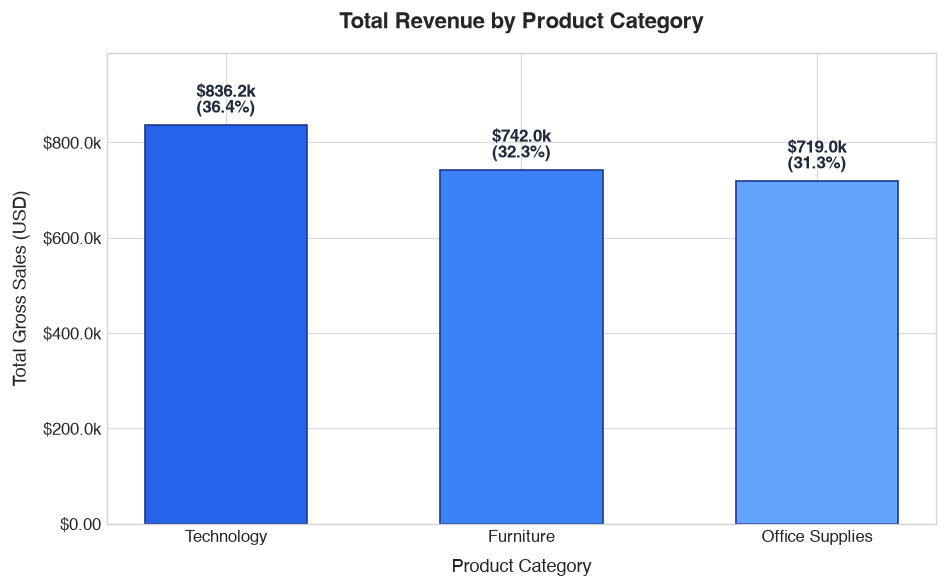

In [16]:
fig1 = plot_sales_by_category(df_cleaned, output_path=project_root / 'outputs' / 'figures' / '01_sales_by_category.png')
plt.show()


### 17.2 Profit by Category
- **Question:** How does net profitability differ across categories?
- **Method:** Bar chart aggregating total $\sum(\text{profit})$ by `category`.
- **Result:** Technology contributed $145,454.95 (50.79% of profit, 17.40% margin), Office Supplies contributed $122,490.80 (42.77% of profit, 17.04% margin), and Furniture contributed $18,451.27 (6.44% of profit, 2.49% margin).
- **Interpretation:** Despite accounting for nearly a third of sales, Furniture generated only 6.44% of net profit, associated with heavy discounts in Tables (-$17,725.48 loss).


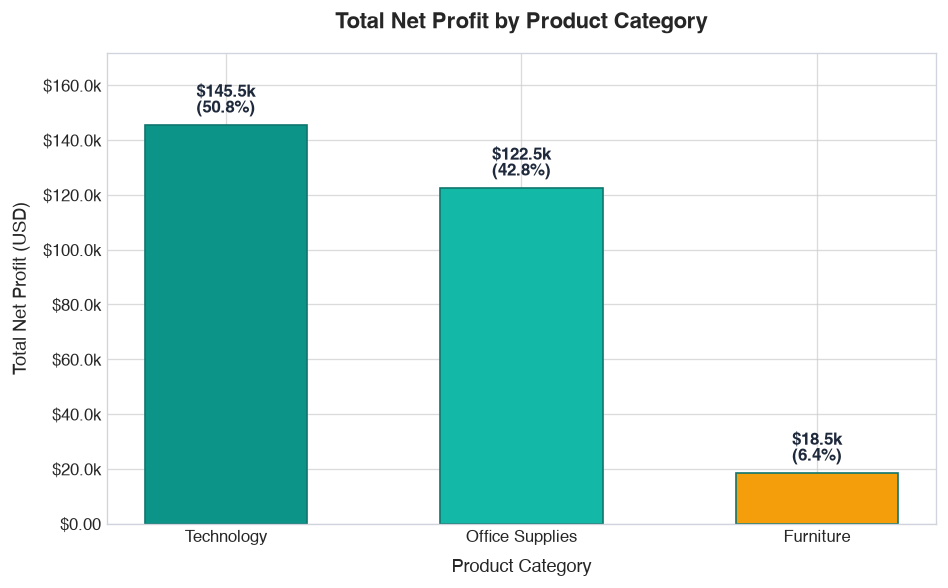

In [17]:
fig2 = plot_profit_by_category(df_cleaned, output_path=project_root / 'outputs' / 'figures' / '02_profit_by_category.png')
plt.show()


### 17.3 Sales by Region
- **Question:** How is gross revenue distributed geographically?
- **Method:** Bar chart aggregating total $\sum(\text{sales})$ by `region`.
- **Result:** West: $725,457.82 (31.58%), East: $678,781.24 (29.55%), Central: $501,239.89 (21.82%), South: $391,721.90 (17.05%).
- **Interpretation:** Coastal regions (West and East) represent over 61% of total enterprise volume.


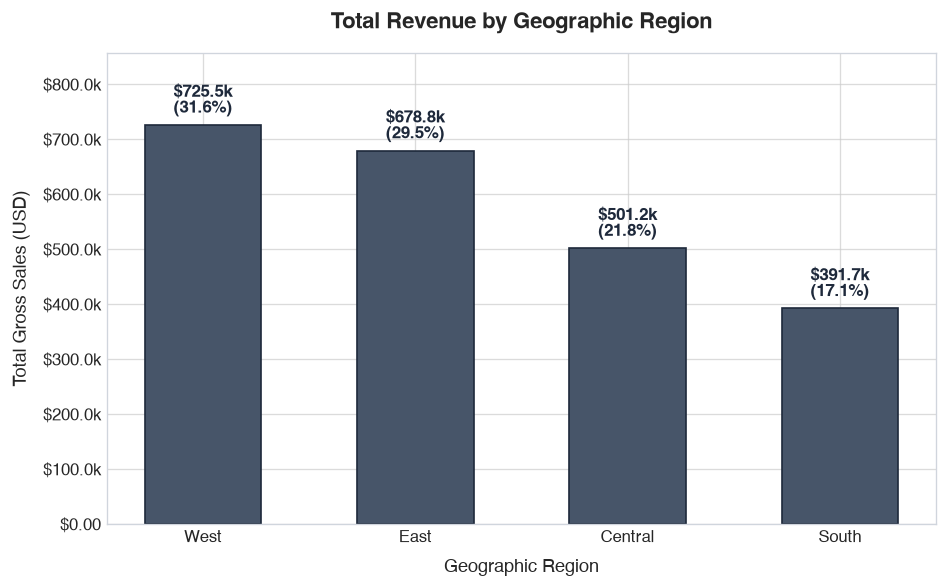

In [18]:
fig3 = plot_sales_by_region(df_cleaned, output_path=project_root / 'outputs' / 'figures' / '03_sales_by_region.png')
plt.show()


### 17.4 Monthly Sales Trend
- **Question:** How does revenue change over time across multi-year cycles?
- **Method:** Multi-year line chart with 3-month moving average across 48 months (2014–2017).
- **Result:** Consistent year-over-year expansion with recurring volume acceleration in September and peak sales during Q4 (November and December).
- **Interpretation:** Seasonal demand accelerates in late summer and reaches maximum volume during the holiday quarter.


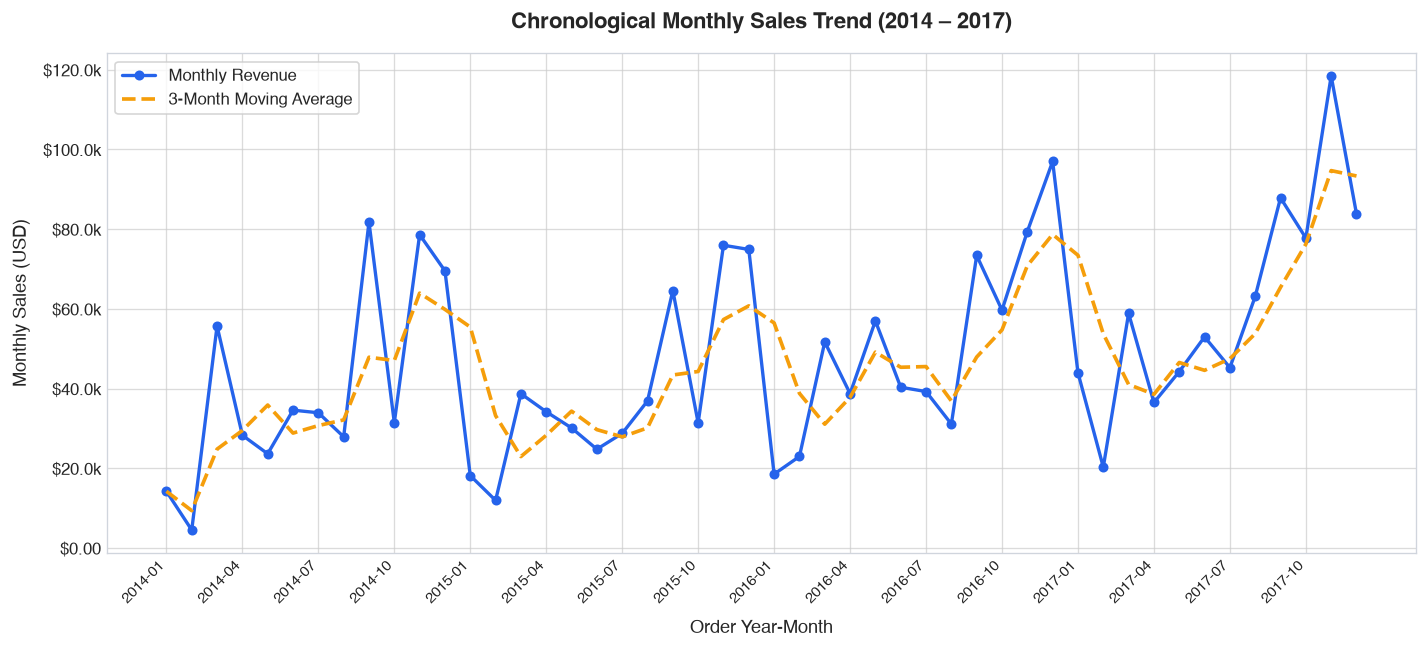

In [19]:
fig4 = plot_monthly_sales_trend(df_cleaned, output_path=project_root / 'outputs' / 'figures' / '04_monthly_sales_trend.png')
plt.show()


### 17.5 Sales Distribution
- **Question:** How are individual line-item sales distributed?
- **Method:** Dual-panel histogram comparing raw linear scale vs. $\log_{10}(\text{sales})$.
- **Result:** The raw sales distribution is strongly right-skewed ($\text{Mean } \$229.86 \gg \text{Median } \$54.49, S = +12.97$). Log transformation produces a more symmetric representation.
- **Interpretation:** Feature scaling and log transformation should be evaluated in downstream ML modeling.


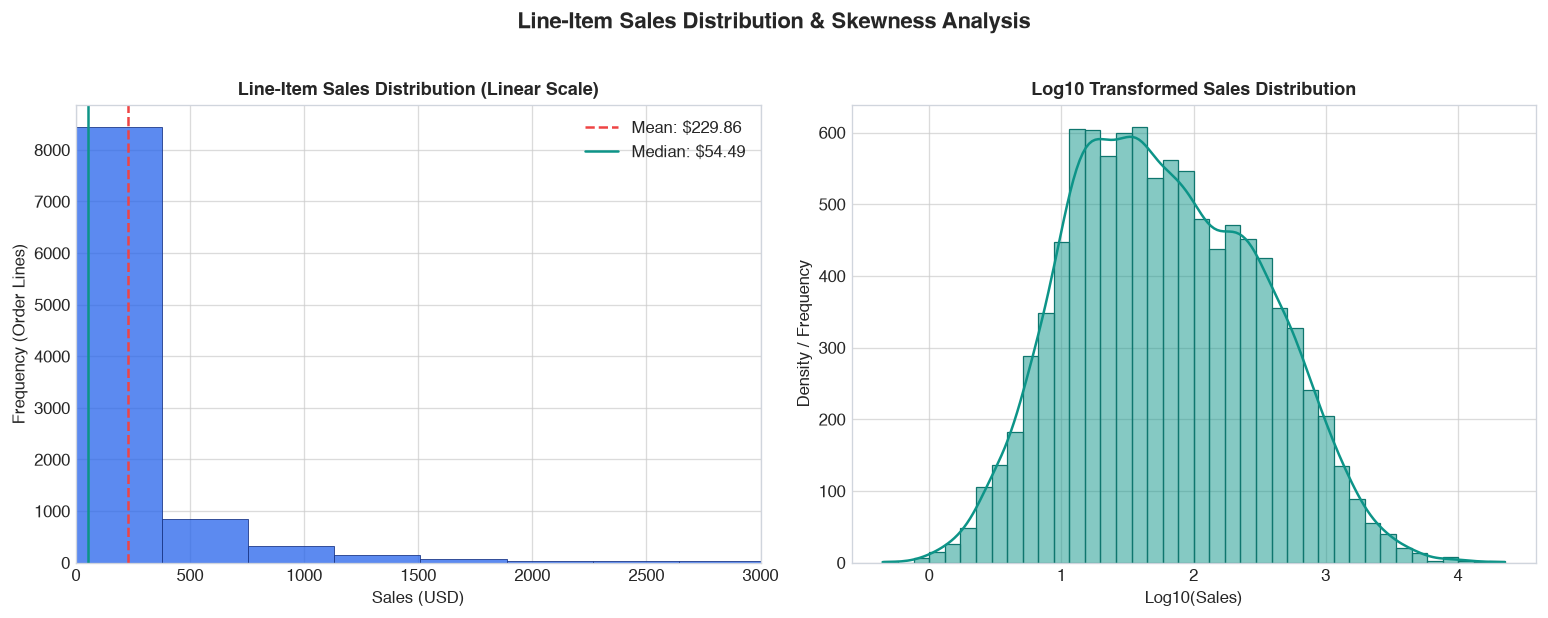

In [20]:
fig5 = plot_sales_distribution(df_cleaned, output_path=project_root / 'outputs' / 'figures' / '05_sales_distribution.png')
plt.show()


### 17.6 Top Products by Revenue
- **Question:** Which individual products generate the highest sales?
- **Method:** Horizontal bar chart of top 10 products by $\sum(\text{sales})$.
- **Result:** The *Canon imageCLASS 2200 Advanced Copier* generated $61,599.82 in sales and $25,199.93 in profit (40.91% profit margin).
- **Interpretation:** High-ticket commercial hardware represents disproportionate revenue and profit contributions.


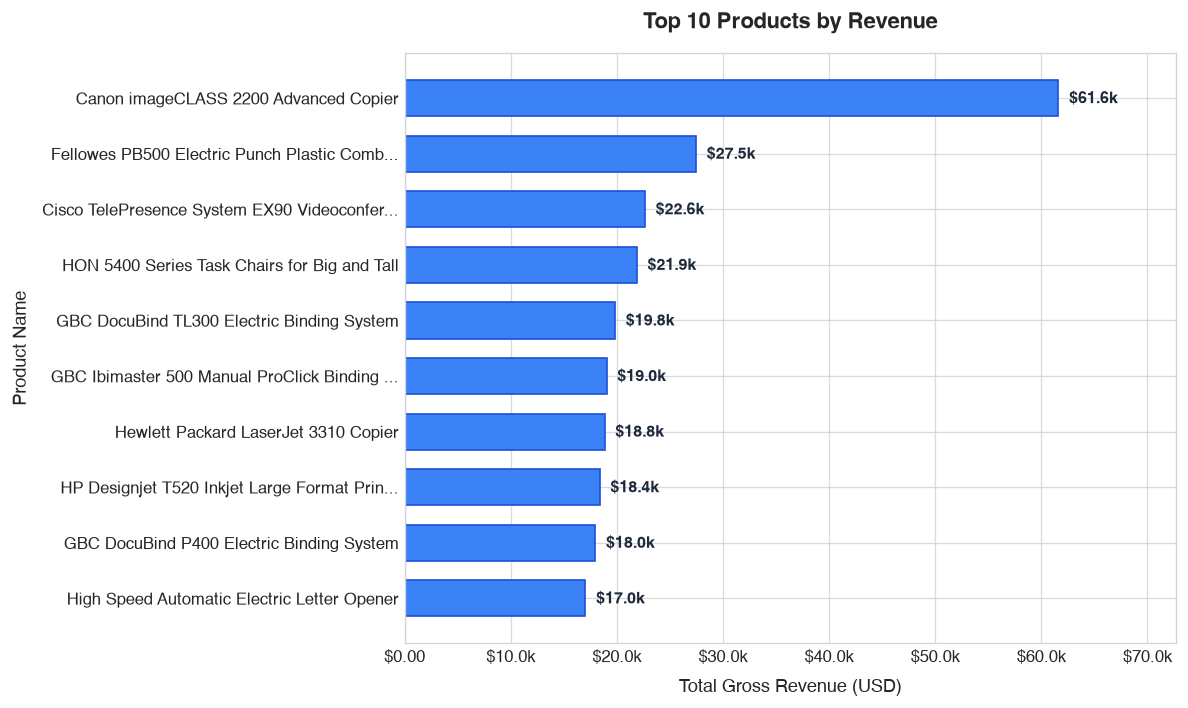

In [21]:
fig6 = plot_top_products_by_revenue(df_cleaned, output_path=project_root / 'outputs' / 'figures' / '06_top_products_by_revenue.png', top_n=10)
plt.show()


### 17.7 Quantity vs. Sales
- **Question:** Is there a relationship between quantity and sales?
- **Method:** Scatter plot with linear trendline and Pearson correlation ($r = +0.2008$).
- **Result:** A weak positive linear association exists ($r = +0.2008$).
- **Interpretation:** Quantity alone accounts for only a minor portion of sales variance; unit price variation across catalog items is the primary factor.


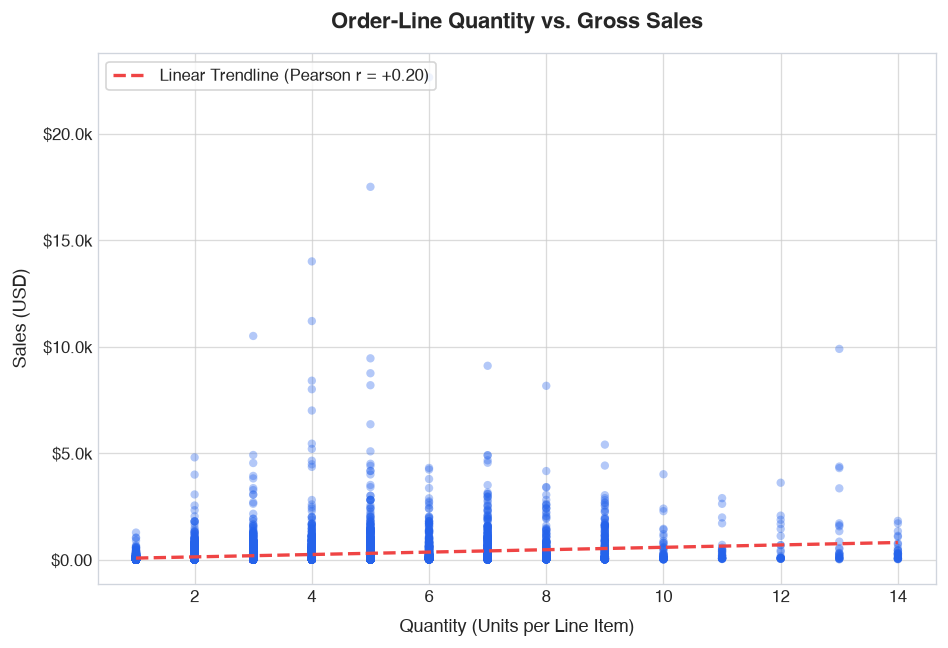

In [22]:
fig7 = plot_quantity_vs_sales(df_cleaned, output_path=project_root / 'outputs' / 'figures' / '07_quantity_vs_sales.png')
plt.show()


### 17.8 Correlation Heatmap
- **Question:** What linear relationships exist among numerical transaction features?
- **Method:** Annotated Pearson correlation heatmap across continuous variables.
- **Result:** `sales` and `profit` show moderate positive linear association ($r = +0.4791$), `discount` and `profit` show moderate negative linear association ($r = -0.2195$), and `sales` and `unit_price` show strong positive correlation ($r = +0.8894$).
- **Interpretation:** Observational evidence indicates that higher discounts coincide with lower profitability in this dataset.


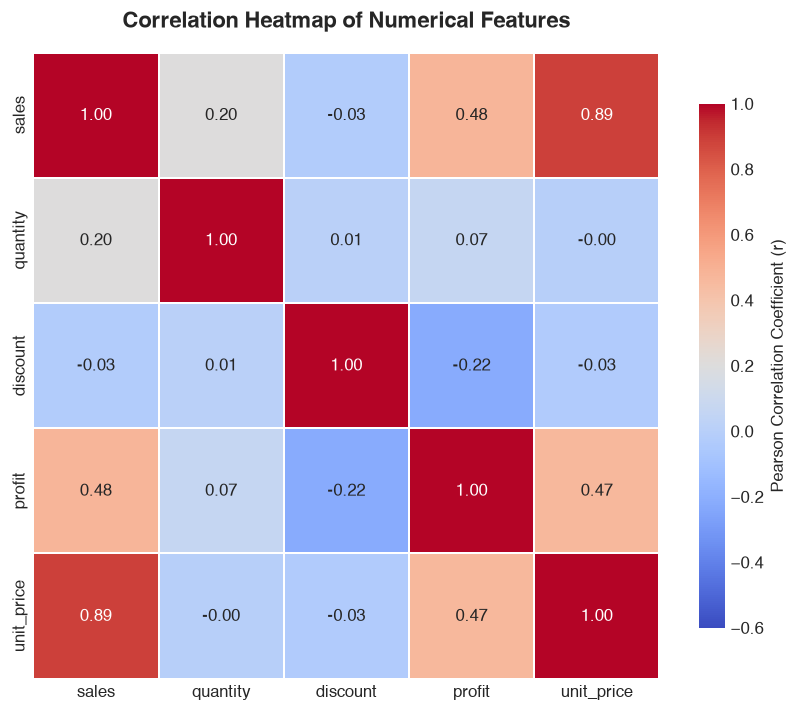

In [23]:
fig8 = plot_correlation_heatmap(df_cleaned, output_path=project_root / 'outputs' / 'figures' / '08_correlation_heatmap.png')
plt.show()


### 17.9 Discount vs. Profitability
- **Question:** How does profitability vary across discount tiers?
- **Method:** Bar chart aggregating net profit and margin % by applied discount level.
- **Result:** Transactions with discounts $\le 20\%$ yielded **+\$421,773.08** in total profit. Transactions with discounts $\ge 30\%$ accumulated **-\$135,376.06** in net losses.
- **Interpretation:** Higher discount levels were associated with lower aggregate profitability in this dataset.


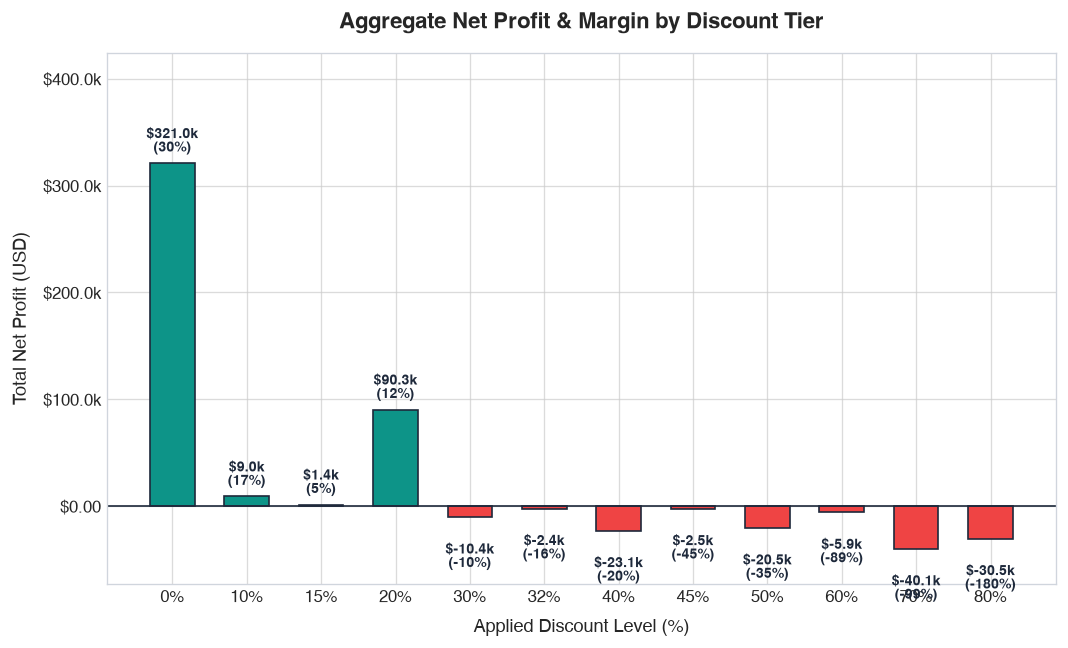

In [24]:
fig9 = plot_discount_profitability(df_cleaned, output_path=project_root / 'outputs' / 'figures' / '09_discount_vs_profitability.png')
plt.show()


### 17.10 Profit Margin by Category
- **Question:** How do category profit margins compare to revenue rankings?
- **Method:** Bar chart of $(\sum\text{profit} / \sum\text{sales}) \times 100$ by `category`.
- **Result:** Technology (17.40%) and Office Supplies (17.04%) achieve strong margins, whereas Furniture achieves 2.49%.
- **Interpretation:** Gross sales rank does not mirror margin efficiency; category-level monitoring is required.


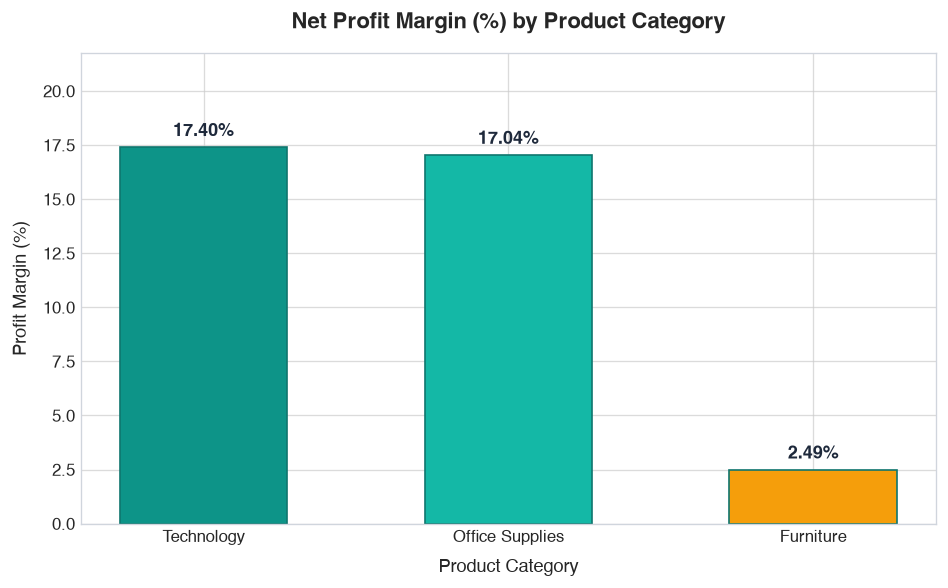

In [25]:
fig10 = plot_category_profit_margin(df_cleaned, output_path=project_root / 'outputs' / 'figures' / '10_profit_margin_by_category.png')
plt.show()


## 18. Key Insights (Evidence-Based)

1. **Technology Generates Majority of Net Profits:**
   - *Observed Fact:* Technology delivered **$145,454.95 (50.79% of total net profits)** on **$836,154.03 in sales (36.40% share)** with a **17.40% margin**.
   - *Interpretation:* Commercial technology equipment is the highest-margin segment in the dataset.

2. **Furniture Exhibits Margin Dilution:**
   - *Observed Fact:* Furniture generated **$741,999.80 in sales (32.30% share)** but yielded only **$18,451.27 in profit (6.44% share)** with a **2.49% margin**. Tables operated at an aggregate net loss of **-$17,725.48**.
   - *Interpretation:* Heavy discounting in specific furniture sub-categories coincided with severe margin erosion.

3. **Discount Levels Associated with Commercial Losses Beyond 20%:**
   - *Observed Fact:* Discounts $\le 20\%$ accumulated **+$421,773.08 in profit**, whereas discounts $\ge 30\%$ accumulated **-$135,376.06 in cumulative net losses**.
   - *Interpretation:* Promotional pricing strategies above 20% were associated with unprofitable transactions in this dataset.

4. **Late-Year & Q4 Demand Acceleration:**
   - *Observed Fact:* Monthly sales accelerate in September and reach their annual peak during the fourth quarter (November and December).
   - *Interpretation:* Operational inventory planning and logistics capacity must ramp up ahead of Q4.

5. **Top-Line Volume Does Not Guarantee Profitability:**
   - *Observed Fact:* The #1 highest-revenue customer (Sean Miller: $25,043.05 sales across 5 orders) produced a **-$1,980.74 net loss**, and the #3 revenue product (Cisco TelePresence System: $22,638.48 sales) generated a **-$1,811.08 net loss**.
   - *Interpretation:* Commercial incentives must align with bottom-line net contribution rather than top-line revenue alone.


## 19. Limitations & Confounding Factors
- **Observational Nature:** This analysis is strictly observational. Correlations ($r$) do not establish causal relationships.
- **Unmeasured Variables:** The dataset lacks detailed variable-level logistics costs, warehouse storage fees, advertising spend, and supplier acquisition costs.
- **Linearity Assumption:** Pearson correlation assesses linear associations and does not capture non-linear relationships.


## 20. Machine Learning Readiness & Target Leakage Prevention

### Potential Predictive Formulations:
1. **Binary Classification (Order Profitability):**
   - **Target:** $\text{profitable\_order} = 1 \text{ if } \text{order\_profit} > 0 \text{ else } 0$
   - **Class Balance:** 79.26% profitable vs. 20.40% loss-making orders.
2. **Regression (Profit / Revenue Forecasting):**
   - **Target:** Continuous `order_profit` or `sales`.
3. **Customer Analytics (RFM Segmentation):**
   - Recency, Frequency, and Monetary value clustering via K-Means.

### Data Leakage Awareness & Prevention:
- **Target Leakage Risk:** If predicting order profitability *before* order completion, using features derived from final discounts, post-order shipping duration, or final line-item profit will leak target information.
- **ML Best Practice:** Any future modeling pipeline must explicitly define:
  1. Prediction timestamp (e.g., at checkout request).
  2. Features available strictly *at or before* that timestamp (e.g., customer historical RFM, product category, baseline price).
  3. Preprocessing (log transformation, standard scaling, one-hot encoding) fit strictly on training splits.


## 21. Conclusion
- **100% Data Integrity:** Verified zero missing values, zero duplicates, and zero record loss across 9,994 line items.
- **KPI Precision:** Formulated order-level AOV ($458.61) distinctly from line-item mean ($229.86).
- **Statistical Rigor:** Quantified distribution skewness and Pearson associations without unsupported causal claims.
- **Production Reproducibility:** Modular codebase (`src/`), automated pipeline (`main.py`), and test suite (`tests/`) ready for portfolio review.
